# 01. 구조적 인과 모델(SCM) 기초

TabPFN은 학습용 합성 데이터셋을 **구조적 인과 모델(Structural Causal Model, SCM)** 로 만듭니다(논문 4.3절). 이 노트북에서는 논문을 읽기 전에 SCM이 무엇인지, SCM에서 데이터를 어떻게 뽑는지, TabPFN이 SCM으로 데이터셋을 어떻게 만드는지를 코드와 그림으로 익힙니다.

인과 추론 이론 전체를 다루지는 않습니다. TabPFN 논문은 자기 방법이 Pearl의 인과 사다리(ladder of causation)에서 "rung 1.5"에 있다고 말합니다. 인과 추론을 하지는 않고, 현실의 데이터셋이 SCM에서 나왔다고 가정한 채 관측 데이터로 예측만 한다는 뜻입니다. 그래서 여기서도 SCM으로 데이터가 만들어지는 과정에 집중합니다.

다루는 흐름:

1. 상관만으로는 데이터가 만들어진 과정을 알 수 없다
2. SCM의 정의 — DAG + 구조 방정식 + 노이즈
3. SCM에서 샘플링하기 — 위상 순서대로 계산
4. 세 가지 기본 구조 — chain, fork, collider
5. 개입 $do(\cdot)$ — SCM이 "인과" 모델인 이유
6. 무작위 SCM으로 표 데이터셋 만들기 — TabPFN prior의 축소판

## `minipfn` 불러오기

다른 노트북과 같은 import shim입니다. 이 노트북은 `notebooks/02_tabpfn/` 아래에 있으므로 저장소 루트는 두 단계 위입니다.

In [1]:
try:
    import minipfn
except ImportError:
    import sys
    from pathlib import Path

    sys.path.insert(0, str(Path.cwd().parents[1] / "src"))
    import minipfn

In [2]:
import matplotlib.pyplot as plt
import numpy as np

# rng = random number generator(난수 생성기). 노이즈 등 모든 무작위 값을 여기서 뽑는다.
# 시드 0으로 고정해 실행할 때마다 같은 난수가 나오게 한다.
rng = np.random.default_rng(0)

In [3]:
def draw_dag(ax, edges, pos, colors=None, node_size=900, labels=True, title=None):
    # edges: [(원인, 결과), ...], pos: {노드: (x, y)}
    colors = colors or {}
    shrink = np.sqrt(node_size) / 2
    for u, v in edges:
        ax.annotate(
            "",
            xy=pos[v],
            xytext=pos[u],
            arrowprops=dict(arrowstyle="-|>", color="gray", lw=1, shrinkA=shrink, shrinkB=shrink),
        )
    for node, (x, y) in pos.items():
        ax.scatter(x, y, s=node_size, color=colors.get(node, "white"), edgecolor="black", zorder=3)
        if labels:
            ax.text(x, y, node, ha="center", va="center", fontsize=9, zorder=4)
    ax.set_title(title)
    ax.axis("off")
    ax.margins(0.15)

## 1. 상관만으로는 데이터가 만들어진 과정을 알 수 없다

여름에는 아이스크림과 선크림이 함께 많이 팔립니다. 두 판매량은 강하게 상관되어 있지만, 아이스크림이 선크림 판매를 늘리는 것은 아닙니다. 둘 다 **기온**이라는 공통 원인의 영향을 받을 뿐입니다.

이 상황을 숫자로 만들어 봅니다. 기온을 먼저 뽑고, 그 기온으로 두 판매량을 각각 계산합니다.

corr(ice, sunscreen) = 0.74


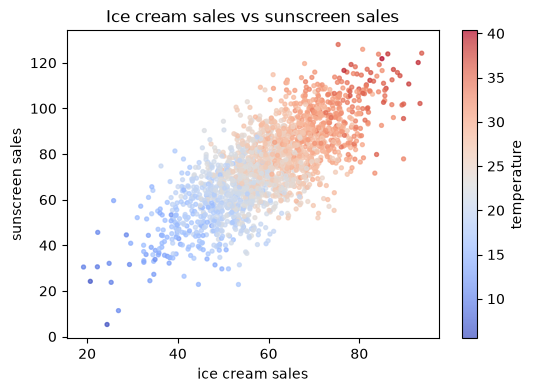

In [4]:
n = 2000
temp = 25 + 5 * rng.standard_normal(n)  # 기온 (°C)
ice = 10 + 2 * temp + 5 * rng.standard_normal(n)  # 아이스크림 판매량
sunscreen = 3 * temp + 10 * rng.standard_normal(n)  # 선크림 판매량

print(f"corr(ice, sunscreen) = {np.corrcoef(ice, sunscreen)[0, 1]:.2f}")

fig, ax = plt.subplots(figsize=(6, 4))
sc = ax.scatter(ice, sunscreen, c=temp, cmap="coolwarm", s=8, alpha=0.7)
fig.colorbar(sc, ax=ax, label="temperature")
ax.set_xlabel("ice cream sales")
ax.set_ylabel("sunscreen sales")
ax.set_title("Ice cream sales vs sunscreen sales")
plt.show()

두 판매량만 보면 뚜렷한 양의 관계가 있습니다. 하지만 "아이스크림을 사러 온 손님이 선크림도 함께 산다"처럼 아이스크림 판매가 선크림 판매를 직접 늘리는, 전혀 다른 과정에서도 같은 모양의 산점도가 나올 수 있습니다(5절에서 직접 확인합니다). 데이터가 **어떤 과정으로 만들어졌는지**를 명시적으로 적는 도구가 SCM입니다.

## 2. SCM의 정의 — DAG + 구조 방정식 + 노이즈

SCM은 변수마다 "이 변수는 어떤 변수들로부터 어떻게 만들어지는가"를 식 하나로 적은 모델입니다. 논문 4.3절의 정의는 다음과 같습니다.

$$
z_i = f_i\big(z_{\mathrm{PA}_G(i)},\; \epsilon_i\big)
$$

- $z_i$: $i$번째 변수(노드)
- $\mathrm{PA}_G(i)$: 그래프 $G$에서 $z_i$의 **부모**, 즉 $z_i$에 직접 영향을 주는 변수들
- $f_i$: 부모 값과 노이즈로 $z_i$를 정하는 **결정적 함수**(구조 방정식)
- $\epsilon_i$: 다른 노이즈와 독립인 **노이즈**. 모델이 설명하지 않는 나머지 요인입니다.

그래프 $G$는 원인에서 결과로 향하는 화살표로 이루어진 **DAG**(directed acyclic graph)입니다. 순환이 없어야 "어느 변수가 먼저 정해지는가"라는 순서가 생깁니다.

1절의 예를 SCM으로 쓰면 다음과 같습니다.

$$
\begin{aligned}
\text{temp} &= 25 + 5\,\epsilon_1 \\
\text{ice} &= 10 + 2\,\text{temp} + 5\,\epsilon_2 \\
\text{sunscreen} &= 3\,\text{temp} + 10\,\epsilon_3
\end{aligned}
$$

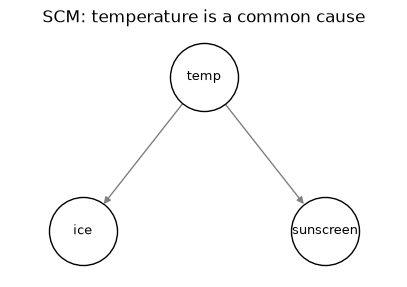

In [5]:
fig, ax = plt.subplots(figsize=(5, 3.2))
draw_dag(
    ax,
    edges=[("temp", "ice"), ("temp", "sunscreen")],
    pos={"temp": (1.2, 1), "ice": (0, 0), "sunscreen": (2.4, 0)},
    node_size=2400,
    title="SCM: temperature is a common cause",
)
ax.margins(0.3)
plt.show()

## 3. SCM에서 샘플링하기 — 위상 순서대로 계산

DAG에는 순환이 없으므로 부모가 자식보다 먼저 오도록 노드를 줄 세울 수 있습니다(위상 정렬, topological sort). 그 순서대로 노이즈를 뽑고 식을 계산하면, SCM이 정의하는 결합분포에서 샘플이 나옵니다. 이것을 ancestral sampling이라고 합니다.

아래 `sample_scm`은 부모 목록과 구조 방정식만 받으면 어떤 SCM이든 샘플링합니다. `do` 인자는 5절에서 씁니다.

In [6]:
def topological_order(parents):
    # 부모가 모두 정해진 노드부터 차례로 꺼낸다 (DAG라서 항상 끝난다).
    order, done = [], set()
    while len(order) < len(parents):
        for node, pa in parents.items():
            if node not in done and all(p in done for p in pa):
                order.append(node)
                done.add(node)
    return order


def sample_scm(parents, equations, n, rng, do=None):
    # parents: {노드: [부모, ...]}, equations: {노드: f(부모 값 dict, 노이즈)}
    # do: {노드: 값} — 해당 노드의 식을 상수로 바꿔 끼운다 (5절).
    do = do or {}
    values = {}
    for node in topological_order(parents):
        if node in do:
            values[node] = np.full(n, float(do[node]))  # 개입: 식 대신 상수
            continue
        # 1) 부모 값을 모은다. 위상 순서로 돌기 때문에 부모는 이미 values에 있다.
        parent_values = {p: values[p] for p in parents[node]}
        # 2) 이 노드의 노이즈 ε를 뽑는다.
        noise = rng.standard_normal(n)
        # 3) 구조 방정식 f에 넣어 값을 계산한다: z = f(부모 값, ε)
        f = equations[node]
        values[node] = f(parent_values, noise)
    return values

In [7]:
confounded_parents = {"temp": [], "ice": ["temp"], "sunscreen": ["temp"]}
confounded_equations = {
    "temp": lambda pa, e: 25 + 5 * e,
    "ice": lambda pa, e: 10 + 2 * pa["temp"] + 5 * e,
    "sunscreen": lambda pa, e: 3 * pa["temp"] + 10 * e,
}

data = sample_scm(confounded_parents, confounded_equations, n, rng)
print("위상 순서:", topological_order(confounded_parents))
print(f"corr(ice, sunscreen) = {np.corrcoef(data['ice'], data['sunscreen'])[0, 1]:.2f}")

위상 순서: ['temp', 'ice', 'sunscreen']
corr(ice, sunscreen) = 0.76


`sample_scm`의 for 문이 ice 차례에서 하는 일을 실제 값으로 풀어 보면 다음과 같습니다.

1. `parent_values = {"temp": values["temp"]}`: ice의 부모는 temp 하나이고, temp는 바로 전 단계에서 계산되어 있습니다.
2. `noise = rng.standard_normal(n)`: ice의 노이즈 $\epsilon_2$를 n개 뽑습니다.
3. `f = equations["ice"]`는 `lambda pa, e: 10 + 2 * pa["temp"] + 5 * e`입니다. 여기에 `pa = parent_values`, `e = noise`를 넣으면 `values["ice"] = 10 + 2 * temp + 5 * noise`가 됩니다. 2절의 식 $\text{ice} = 10 + 2\,\text{temp} + 5\,\epsilon_2$ 그대로입니다.

즉 `equations`의 lambda는 "부모 값 `pa`와 노이즈 `e`를 받아 이 노드의 값을 돌려주는 함수"이고, `parents`는 그 함수에 어떤 부모 값을 넘길지 정합니다.

위상 순서대로 노드를 하나씩 계산하는 과정을 그림으로 보면 다음과 같습니다. 각 단계에서 계산하는 노드(빨강)의 부모는 모두 이미 계산되어 있습니다(파랑).

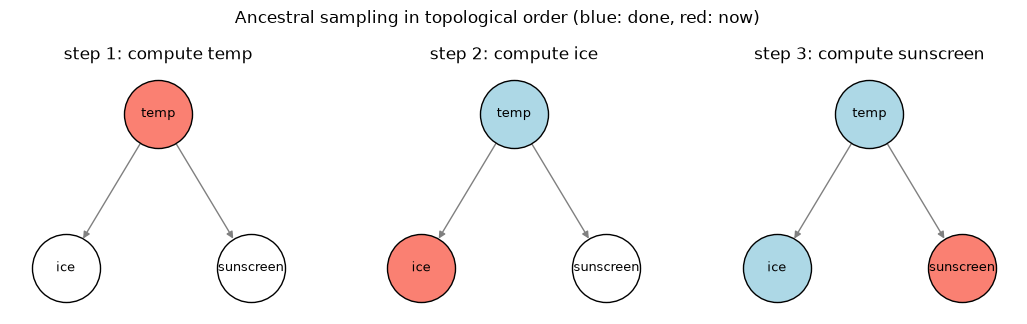

In [8]:
order = topological_order(confounded_parents)
edges = [(p, node) for node, pa in confounded_parents.items() for p in pa]
pos = {"temp": (1.2, 1), "ice": (0, 0), "sunscreen": (2.4, 0)}

fig, axes = plt.subplots(1, len(order), figsize=(13, 3.2))
for step, (ax, node) in enumerate(zip(axes, order, strict=True), start=1):
    # 이미 계산한 노드는 파랑, 지금 계산하는 노드는 빨강
    colors = {done: "lightblue" for done in order[: step - 1]} | {node: "salmon"}
    draw_dag(ax, edges, pos, colors, node_size=2400, title=f"step {step}: compute {node}")
    ax.margins(0.3)
fig.suptitle("Ancestral sampling in topological order (blue: done, red: now)", y=1.06)
plt.show()

2절의 식을 그대로 옮겼으니 1절과 같은 분포의 데이터가 나옵니다. SCM은 "변수를 하나씩 순서대로 만들어 가는 프로그램"이라고 봐도 됩니다. TabPFN의 prior는 이런 프로그램을 무작위로 만들어 실행합니다(6절).

## 4. 세 가지 기본 구조 — chain, fork, collider

변수 세 개 A, B, C를 잇는 방식은 기본적으로 세 가지입니다. 큰 DAG도 이 조각들로 이루어지고, 어떤 조각이냐에 따라 변수 사이의 상관 패턴이 달라집니다.

- **chain** $A \to B \to C$: A가 B를 거쳐 C에 영향을 줍니다.
- **fork** $A \leftarrow B \to C$: B가 A와 C의 공통 원인입니다(1절의 기온).
- **collider** $A \to B \leftarrow C$: A와 C가 함께 B를 만듭니다.

구조마다 A와 C의 상관을 그대로 구한 값과, B의 영향을 회귀로 빼낸 뒤 구한 값을 비교합니다. 후자는 B를 고정했을 때의 상관으로, **편상관**(partial correlation)이라고 합니다.

구조          corr(A, C)  corr(A, C | B)


chain             0.81           -0.02
fork              0.79           -0.00
collider         -0.01           -0.81


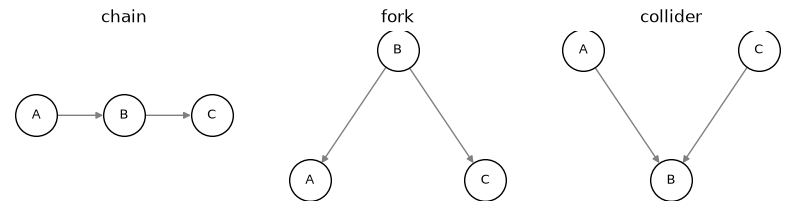

In [9]:
structures = {
    "chain": (
        {"A": [], "B": ["A"], "C": ["B"]},
        {
            "A": lambda pa, e: e,
            "B": lambda pa, e: pa["A"] + 0.5 * e,
            "C": lambda pa, e: pa["B"] + 0.5 * e,
        },
        {"A": (0, 0), "B": (1, 0), "C": (2, 0)},
    ),
    "fork": (
        {"B": [], "A": ["B"], "C": ["B"]},
        {
            "B": lambda pa, e: e,
            "A": lambda pa, e: pa["B"] + 0.5 * e,
            "C": lambda pa, e: pa["B"] + 0.5 * e,
        },
        {"A": (0, 0), "B": (1, 0.6), "C": (2, 0)},
    ),
    "collider": (
        {"A": [], "C": [], "B": ["A", "C"]},
        {
            "A": lambda pa, e: e,
            "C": lambda pa, e: e,
            "B": lambda pa, e: pa["A"] + pa["C"] + 0.5 * e,
        },
        {"A": (0, 0.6), "B": (1, 0), "C": (2, 0.6)},
    ),
}


def partial_corr(a, c, b):
    # b로 선형 회귀한 잔차끼리의 상관 = b를 고정했을 때 a와 c의 상관
    ra = a - np.polyval(np.polyfit(b, a, 1), b)
    rc = c - np.polyval(np.polyfit(b, c, 1), b)
    return np.corrcoef(ra, rc)[0, 1]


fig, axes = plt.subplots(1, 3, figsize=(10, 2.2))
print(f"{'구조':<10}{'corr(A, C)':>12}{'corr(A, C | B)':>16}")
for ax, (name, (parents, equations, pos)) in zip(axes, structures.items(), strict=True):
    edges = [(p, node) for node, pa in parents.items() for p in pa]
    draw_dag(ax, edges, pos, title=name)
    v = sample_scm(parents, equations, 5000, rng)
    corr = np.corrcoef(v["A"], v["C"])[0, 1]
    print(f"{name:<10}{corr:>12.2f}{partial_corr(v['A'], v['C'], v['B']):>16.2f}")
plt.show()

결과를 정리하면 다음과 같습니다.

| 구조 | A와 C의 상관 | B를 고정하면 |
|---|---|---|
| chain | 있음 | 사라짐 |
| fork | 있음 | 사라짐 |
| collider | 없음 | **생김** |

chain과 fork에서는 A와 C 사이의 정보가 모두 B를 거쳐 흐르므로, B를 고정하면 상관이 사라집니다. collider는 반대입니다. A와 C는 서로 독립이지만, B 값을 알고 나면 "A가 크면 C는 작아야 B가 이 값이 된다"는 관계가 생깁니다. 아래 그림에서 B가 큰 샘플만 골라 보면 A와 C 사이에 음의 상관이 나타납니다.

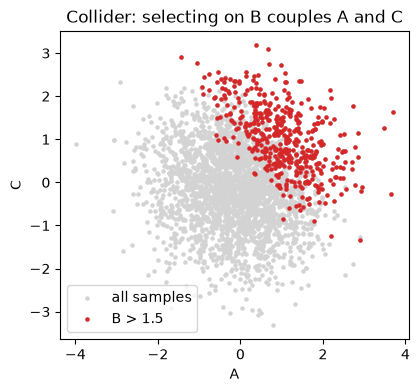

In [10]:
parents, equations, _ = structures["collider"]
v = sample_scm(parents, equations, 3000, rng)
selected = v["B"] > 1.5

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.scatter(v["A"], v["C"], s=5, color="lightgray", label="all samples")
ax.scatter(v["A"][selected], v["C"][selected], s=5, color="C3", label="B > 1.5")
ax.set_xlabel("A")
ax.set_ylabel("C")
ax.set_title("Collider: selecting on B couples A and C")
ax.legend(loc="lower left")
plt.show()

표 데이터의 feature와 target도 DAG 안의 노드라고 보면, 어떤 feature가 target과 상관되는지, 어떤 feature가 다른 feature가 있을 때 쓸모없어지는지가 그래프에서 노드가 놓인 위치로 정해집니다. SCM prior는 그래프 구조만 바꿔서 이런 다양한 의존 패턴을 만들어 냅니다.

## 5. 개입 $do(\cdot)$ — SCM이 "인과" 모델인 이유

SCM은 관측 데이터의 분포만 정하는 게 아니라, "변수 하나를 바깥에서 강제로 바꾸면 어떻게 되는가"에도 답합니다. 이것을 **개입**(intervention)이라 하고 $do(X = x)$로 씁니다. SCM에서 개입은 간단합니다. $X$의 구조 방정식을 상수 $x$로 바꿔 끼우고, 나머지 식은 그대로 둔 채 SCM 프로그램을 처음부터 다시 실행합니다. `sample_scm`의 `do` 인자가 이 일을 합니다.

예를 들어 `sample_scm(..., do={"ice": 40})`은 3절과 같은 순서로 노드를 계산하되, ice 차례에서만 식 $10 + 2\,\text{temp} + 5\,\epsilon_2$ 대신 40을 넣습니다.

1. temp: 평소처럼 $25 + 5\,\epsilon_1$로 뽑습니다. 날씨는 그대로입니다.
2. ice: temp와 상관없이 모든 샘플에서 40입니다. 할인 행사로 판매량을 맞췄다고 생각하면 됩니다.
3. sunscreen: 평소 식대로 부모 값으로 계산합니다.

이렇게 만든 샘플에서 sunscreen의 평균을 내면 $E[\text{sunscreen} \mid do(\text{ice} = 40)]$입니다. 관측 데이터에서 ice가 우연히 40 근처인 샘플만 골라 평균을 내는 것과는 다릅니다. 관측 데이터에서 아이스크림이 40개쯤 팔린 날은 대개 추운 날이고, 그래서 선크림도 적게 팔린 날이기 때문입니다. 두 방법을 직접 비교해 봅니다.

In [11]:
import pandas as pd

x = 40
obs = sample_scm(confounded_parents, confounded_equations, n, rng)
near = np.abs(obs["ice"] - x) < 3  # 관측 데이터에서 ice가 우연히 40 근처인 샘플
intervened = sample_scm(confounded_parents, confounded_equations, n, rng, do={"ice": x})

pd.DataFrame(
    {
        "temp 평균": [obs["temp"][near].mean(), intervened["temp"].mean()],
        "ice 평균": [obs["ice"][near].mean(), intervened["ice"].mean()],
        "sunscreen 평균": [obs["sunscreen"][near].mean(), intervened["sunscreen"].mean()],
    },
    index=["관측: ice ≈ 40인 샘플만 고름", "개입: do(ice = 40)"],
).round(1)

,temp 평균,ice 평균,sunscreen 평균
관측: ice ≈ 40인 샘플만 고름,16.9,40.6,51.0
개입: do(ice = 40),25.2,40.0,75.3


관측 데이터에서 고른 샘플은 기온이 낮은 날이라 선크림 판매량도 낮습니다. 개입한 샘플은 기온이 평소대로라서 선크림 판매량도 평소와 같습니다. 기온이 공통 원인인 SCM에서는 아이스크림 판매량을 바꿔도 선크림 판매량이 움직이지 않는다는 뜻입니다.

이제 x를 40, 50, …, 80으로 바꿔 가며 같은 계산을 반복하고, 1절의 SCM(기온이 공통 원인)과 아이스크림 판매가 선크림 판매를 직접 늘리는 다른 SCM을 비교합니다. 두 SCM 모두 아이스크림 판매량에 대한 선크림 판매량의 관측 기울기가 약 1.2가 되도록 계수를 맞췄습니다.

SCM                                   관측 기울기    개입 기울기
Common cause (temp)                    1.186     0.013
Direct effect (ice -> sunscreen)       1.217     1.203


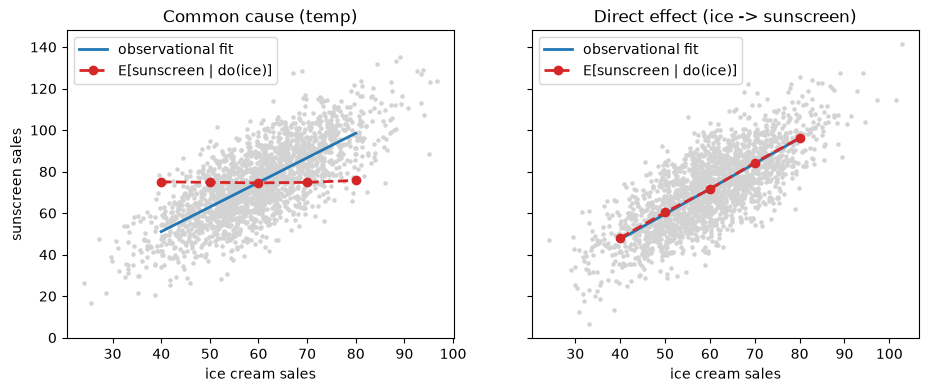

In [12]:
direct_parents = {"temp": [], "ice": ["temp"], "sunscreen": ["ice"]}
direct_equations = {
    "temp": lambda pa, e: 25 + 5 * e,
    "ice": lambda pa, e: 10 + 2 * pa["temp"] + 5 * e,
    "sunscreen": lambda pa, e: 1.2 * pa["ice"] + 12 * e,
}

scms = {
    "Common cause (temp)": (confounded_parents, confounded_equations),
    "Direct effect (ice -> sunscreen)": (direct_parents, direct_equations),
}
ice_grid = np.linspace(40, 80, 5)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
print(f"{'SCM':<34}{'관측 기울기':>10}{'개입 기울기':>10}")
for ax, (name, (parents, equations)) in zip(axes, scms.items(), strict=True):
    obs = sample_scm(parents, equations, n, rng)
    slope, intercept = np.polyfit(obs["ice"], obs["sunscreen"], 1)
    # x마다 ice를 x로 고정한 채 SCM을 처음부터 다시 실행하고, sunscreen 값들의 평균을 낸다.
    do_means = np.array(
        [
            sample_scm(parents, equations, n, rng, do={"ice": x})["sunscreen"].mean()
            for x in ice_grid
        ]
    )
    do_slope = np.polyfit(ice_grid, do_means, 1)[0]
    print(f"{name:<34}{slope:>10.3f}{do_slope:>10.3f}")

    ax.scatter(obs["ice"], obs["sunscreen"], s=5, color="lightgray")
    ax.plot(ice_grid, slope * ice_grid + intercept, color="C0", lw=2, label="observational fit")
    ax.plot(ice_grid, do_means, "o--", color="C3", lw=2, label="E[sunscreen | do(ice)]")
    ax.set_xlabel("ice cream sales")
    ax.set_title(name)
    ax.legend(loc="upper left")
axes[0].set_ylabel("sunscreen sales")
plt.show()

관측 데이터만 보면 두 SCM의 기울기는 거의 같습니다. 개입하면 차이가 드러납니다. 기온이 공통 원인인 SCM에서는 할인 행사로 아이스크림 판매량을 늘려도 선크림 판매량이 그대로이고(기울기 ≈ 0), 아이스크림 판매가 직접 원인인 SCM에서는 관측 기울기만큼 늘어납니다. 관측 분포가 같아도 SCM이 다르면 개입의 결과가 다르다는 점이 SCM을 "인과" 모델로 만듭니다.

TabPFN은 개입을 쓰지 않습니다. 관측 데이터로 예측만 하므로 논문은 스스로를 "rung 1.5"라고 부릅니다. SCM을 쓰는 이유는 인과 효과를 추정하려는 게 아니라, **현실의 표 데이터가 이런 인과 과정에서 만들어진다고 보고** 그 과정을 흉내 내 학습 데이터를 만들기 위해서입니다.

## 6. 무작위 SCM으로 표 데이터셋 만들기 — TabPFN prior의 축소판

지금까지는 SCM을 손으로 적었습니다. TabPFN의 prior는 SCM 자체를 무작위로 뽑습니다. 논문 부록 C.1의 절차를 줄이면 다음과 같습니다.

1. 층 수 $l$과 층당 노드 수 $h$를 뽑아 MLP 모양의 그래프를 만듭니다.
2. 가중치를 뽑고, 간선 일부를 무작위로 지워(dropout) 다양한 DAG를 만듭니다.
3. 각 노드 값은 $z = a(W z_{\text{prev}}) + \epsilon$으로 계산합니다. 활성화 함수 $a$는 {tanh, LeakyReLU, ELU, identity} 중 하나를 고릅니다.
4. 전체 노드 중 일부를 feature $x$로, 하나를 target $y$로 고릅니다. 나머지는 관측되지 않는 노드 $z$입니다.
5. 연속값 target을 무작위 경계로 잘라 클래스로 바꾸고, 클래스 번호를 섞습니다(4.5절).

feature와 target은 그래프 아무 위치에서나 뽑히므로, feature가 target의 원인일 수도, 결과일 수도, target과 무관할 수도 있습니다. 또 4.2절의 단순성(Occam's razor)에 따라 층과 노드가 적은 작은 그래프가 더 자주 뽑히도록 분포를 잡습니다.

아래 구현은 이 절차를 따르되 하이퍼파라미터 분포는 단순하게 바꿨습니다. 논문의 실제 값(부록 E.4)은 TabPFN walkthrough에서 다룹니다.

### 작은 예로 먼저 보기

무작위로 뽑기 전에, 층 3개 × 노드 2개짜리 작은 SCM을 손으로 만들어 4번 단계를 따라가 봅니다. 4번 단계는 두 단계로 나뉩니다.

1. 그래프의 **모든 노드** 값을 계산해 큰 표를 만듭니다. 노드 하나가 열 하나입니다.
2. 그 표에서 **열 몇 개만** 남깁니다. 남긴 열이 feature $x$와 target $y$이고, 버린 열이 관측되지 않는 노드 $z$입니다.

어떤 열을 남길지는 층과 상관없이 정합니다. 그래서 같은 층 안에서도 어떤 노드는 남고 어떤 노드는 버려집니다. 아래 예에서는 설명하기 쉽게 직접 골랐지만, TabPFN은 무작위로 고릅니다.

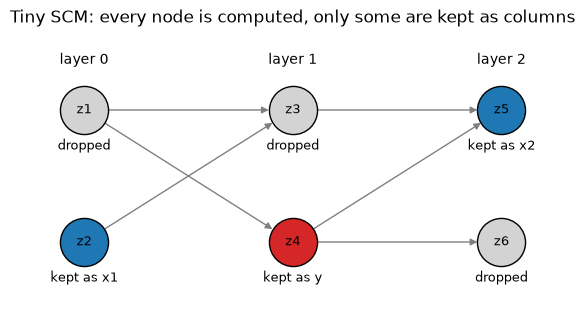

In [13]:
tiny_parents = {
    # layer 0: 노이즈만으로 정해지는 원인 노드
    "z1": [],
    "z2": [],
    # layer 1
    "z3": ["z1", "z2"],
    "z4": ["z1"],
    # layer 2
    "z5": ["z3", "z4"],
    "z6": ["z4"],
}
tiny_equations = {
    "z1": lambda pa, e: e,
    "z2": lambda pa, e: e,
    "z3": lambda pa, e: np.tanh(1.5 * pa["z1"] - pa["z2"]) + 0.1 * e,
    "z4": lambda pa, e: np.tanh(-2 * pa["z1"]) + 0.1 * e,
    "z5": lambda pa, e: np.tanh(pa["z3"] + pa["z4"]) + 0.1 * e,
    "z6": lambda pa, e: np.tanh(1.2 * pa["z4"]) + 0.1 * e,
}
# 표에 남길 열: 노드 이름 -> 데이터셋에서의 이름. 나머지(z1, z3, z6)는 버린다.
kept = {"z2": "x1", "z4": "y", "z5": "x2"}

pos = {"z1": (0, 0), "z2": (0, -1), "z3": (1, 0), "z4": (1, -1), "z5": (2, 0), "z6": (2, -1)}
colors = {node: "lightgray" for node in pos}
for node, name in kept.items():
    colors[node] = "C3" if name == "y" else "C0"
edges = [(p, node) for node, pa in tiny_parents.items() for p in pa]

fig, ax = plt.subplots(figsize=(7, 3.6))
draw_dag(ax, edges, pos, colors, node_size=1200)
for node, (x, y) in pos.items():
    ax.text(
        x, y - 0.3, f"kept as {kept[node]}" if node in kept else "dropped", ha="center", fontsize=9
    )
for k in range(3):
    ax.text(k, 0.35, f"layer {k}", ha="center", fontsize=10)
ax.set_ylim(-1.5, 0.6)
ax.set_title("Tiny SCM: every node is computed, only some are kept as columns")
plt.show()

**1단계: 모든 노드를 계산합니다.** 3절의 `sample_scm`을 그대로 써서 샘플 5개를 뽑으면 노드 6개가 모두 열로 있는 표가 나옵니다.

In [14]:
all_nodes = pd.DataFrame(sample_scm(tiny_parents, tiny_equations, 5, rng)).round(2)
all_nodes

,z1,z2,z3,z4,z5,z6
0,1.66,-1.60,0.88,-0.84,0.15,-0.66
1,0.59,-1.62,1.15,-0.93,0.23,-0.95
2,0.18,1.48,-0.79,-0.46,-0.88,-0.45
3,-0.92,0.42,-0.84,0.74,-0.02,0.81
4,1.35,0.30,0.81,-1.11,-0.28,-1.02


**2단계: 열 몇 개만 남깁니다.** 아래 표가 PFN이 실제로 받는 데이터셋입니다.

In [15]:
dataset = all_nodes[list(kept)].rename(columns=kept)
dataset

,x1,y,x2
0,-1.60,-0.84,0.15
1,-1.62,-0.93,0.23
2,1.48,-0.46,-0.88
3,0.42,0.74,-0.02
4,0.30,-1.11,-0.28


z1, z3, z6 열은 버렸습니다. z1은 feature인 z2와 같은 layer 0에 있고, z3는 target인 z4와 같은 layer 1에 있습니다. 둘 다 표에 남지 않았을 뿐 값은 1단계에서 계산되었고 다른 노드에 영향을 줬습니다. 예를 들어 target y(z4)는 버려진 z1으로만 정해지므로, 데이터셋만 보는 사람에게 z1은 "보이지 않는 원인"입니다. 1절에 비유하면, 표에 아이스크림과 선크림 판매량 열만 있고 기온 열이 없을 때 기온이 z1 같은 노드입니다.

남긴 열과 target의 관계도 그래프가 정합니다. x2(z5)는 y(z4)의 결과이므로 y를 예측하는 데 도움이 됩니다. 반면 x1(z2)에서 y로 가는 경로는 없고, 둘이 공유하는 원인도 없어서 x1은 y와 무관합니다.

In [16]:
ACTIVATIONS = {
    "tanh": np.tanh,
    "leaky_relu": lambda z: np.where(z > 0, z, 0.01 * z),
    "elu": lambda z: np.where(z > 0, z, np.expm1(np.minimum(z, 0))),
    "identity": lambda z: z,
}


def sample_random_scm(n_features, rng):
    # 층 수와 노드 수는 작은 값이 더 자주 나오도록 뽑는다 (단순성).
    n_layers = int(rng.integers(2, 5))
    hidden = int(np.exp(rng.uniform(np.log(4), np.log(16))))
    hidden = max(hidden, -(-(n_features + 1) // (n_layers + 1)))  # 노드가 feature + target보다 많게
    w_std = np.exp(rng.uniform(np.log(0.3), np.log(3)))
    p_drop = rng.uniform(0, 0.8)
    weights = [rng.normal(0, w_std, (hidden, hidden)) for _ in range(n_layers)]
    masks = [rng.random((hidden, hidden)) > p_drop for _ in range(n_layers)]  # False = 지운 간선
    n_nodes = (n_layers + 1) * hidden
    nodes = rng.choice(n_nodes, n_features + 1, replace=False)
    return {
        "n_layers": n_layers,
        "hidden": hidden,
        "activation": str(rng.choice(list(ACTIVATIONS))),
        "noise_std": np.exp(rng.uniform(np.log(1e-3), np.log(0.3))),
        "weights": [w * m for w, m in zip(weights, masks, strict=True)],
        "masks": masks,
        "feature_nodes": nodes[:-1],
        "target_node": nodes[-1],
    }


def sample_dataset(scm, n_samples, max_classes, rng):
    act = ACTIVATIONS[scm["activation"]]
    z = rng.standard_normal((n_samples, scm["hidden"]))  # 첫 층: 원인 노드 (노이즈만으로 정해진다)
    layers = [z]
    for w in scm["weights"]:
        z = act(z @ w) + scm["noise_std"] * rng.standard_normal(z.shape)
        layers.append(z)
    all_nodes = np.concatenate(layers, axis=1)

    x = all_nodes[:, scm["feature_nodes"]]
    x = (x - x.mean(0)) / (x.std(0) + 1e-8)  # 표준화 (부록 C.2.1)
    y_cont = all_nodes[:, scm["target_node"]]

    # 4.5절: 연속 target에서 경계를 뽑아 구간 번호를 클래스로 쓰고, 번호를 섞는다.
    n_classes = int(rng.integers(2, max_classes + 1))
    bounds = np.sort(rng.choice(y_cont, n_classes - 1, replace=False))
    y = rng.permutation(n_classes)[np.searchsorted(bounds, y_cont)]
    return x, y

이제 `sample_random_scm`으로 뽑은 SCM을 같은 방식으로 그려 봅니다. 위의 작은 예를 층과 노드 수만 키운 것입니다. 열(층)은 계산 순서이고, 색은 그 노드를 표의 열로 남겼는지를 나타냅니다.

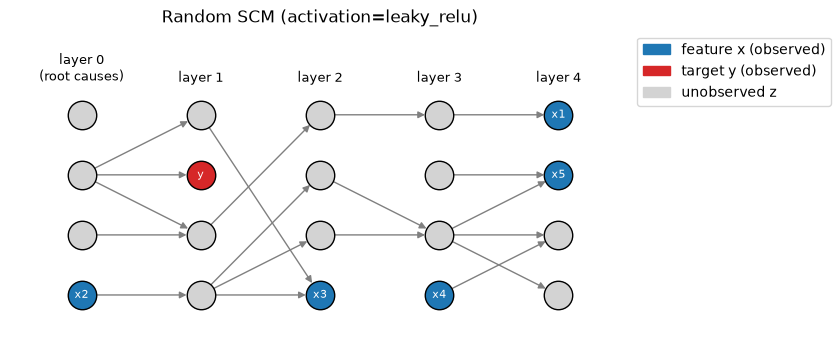

In [17]:
from matplotlib.patches import Patch

scm = sample_random_scm(n_features=5, rng=rng)
h = scm["hidden"]
# 노드 번호 k * h + j = k번째 층의 j번째 노드
pos = {k * h + j: (k, -j) for k in range(scm["n_layers"] + 1) for j in range(h)}

edges = []
for k, mask in enumerate(scm["masks"]):  # mask[i, j]: k층 i번 → k+1층 j번 간선이 남았는가
    for i, j in zip(*np.nonzero(mask), strict=True):
        edges.append((k * h + i, (k + 1) * h + j))

colors = {node: "lightgray" for node in pos}  # 기본은 관측되지 않는 노드 z
names = {}
for i, node in enumerate(scm["feature_nodes"]):
    colors[int(node)] = "C0"
    names[int(node)] = f"x{i + 1}"
colors[int(scm["target_node"])] = "C3"
names[int(scm["target_node"])] = "y"

fig, ax = plt.subplots(figsize=(8, 0.6 * h + 1.5))
draw_dag(ax, edges, pos, colors, node_size=420, labels=False)
for node, name in names.items():
    ax.text(*pos[node], name, ha="center", va="center", fontsize=8, color="white", zorder=4)
for k in range(scm["n_layers"] + 1):
    label = "layer 0\n(root causes)" if k == 0 else f"layer {k}"
    ax.text(k, 0.5, label, ha="center", va="bottom", fontsize=9)
ax.set_ylim(-h + 0.4, 1.4)
ax.set_title(f"Random SCM (activation={scm['activation']})")
ax.legend(
    handles=[
        Patch(color="C0", label="feature x (observed)"),
        Patch(color="C3", label="target y (observed)"),
        Patch(color="lightgray", label="unobserved z"),
    ],
    loc="upper left",
    bbox_to_anchor=(1.0, 1.0),
)
plt.show()

feature가 target보다 왼쪽 층에 있으면 target의 원인 쪽이고, 오른쪽 층에 있으면 target의 결과 쪽입니다. 같은 층에 있으면 서로 직접 이어져 있지는 않지만, 앞 층의 공통 원인을 공유해서 상관될 수 있습니다(1절에서 기온을 공유하는 아이스크림과 선크림처럼). 이어진 경로도 공통 원인도 없으면 target과 무관한 feature가 됩니다. 현실의 표 데이터에도 target의 원인인 열, 결과인 열, 상관없는 열이 섞여 있으므로, prior도 이런 경우를 모두 만들어 냅니다. 논문 Figure 2가 보여 주는 것도 이 구조입니다(*"Inputs x are mapped to the output y through unobserved nodes z"*).

같은 방식으로 feature 2개짜리 데이터셋을 200개 뽑습니다. 무작위로 고른 feature 2개는 target과 거의 무관한 경우가 많습니다. target이 관측되지 않는 다른 노드에 주로 좌우되기 때문입니다. 데이터셋마다 feature로 클래스를 얼마나 맞힐 수 있는지를 "kNN 교차검증 정확도 − 가장 많은 클래스의 비율"(gain)로 재 봅니다.

In [18]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier

datasets = []
for _ in range(200):
    scm = sample_random_scm(n_features=2, rng=rng)
    x, y = sample_dataset(scm, n_samples=300, max_classes=4, rng=rng)
    acc = cross_val_score(KNeighborsClassifier(15), x, y, cv=KFold(3, shuffle=True, random_state=0))
    gain = acc.mean() - np.bincount(y).max() / len(y)
    datasets.append((scm, x, y, gain))

gains = np.array([d[3] for d in datasets])
print(f"gain > 0.15 (feature로 클래스를 꽤 맞힘): {np.mean(gains > 0.15):.0%}")
print(f"gain < 0.05 (거의 못 맞힘):              {np.mean(gains < 0.05):.0%}")

gain > 0.15 (feature로 클래스를 꽤 맞힘): 16%
gain < 0.05 (거의 못 맞힘):              68%


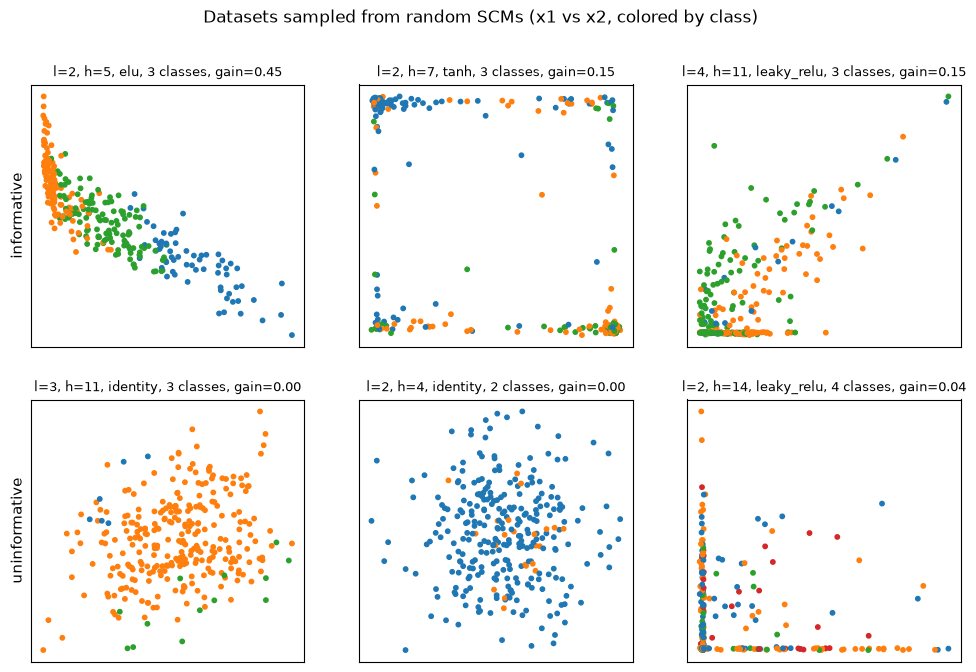

In [19]:
informative = [d for d in datasets if d[3] > 0.15][:3]
uninformative = [d for d in datasets if d[3] < 0.05][:3]

fig, axes = plt.subplots(2, 3, figsize=(12, 7.5))
for ax, (scm, x, y, gain) in zip(axes.flat, informative + uninformative, strict=True):
    ax.scatter(x[:, 0], x[:, 1], c=y, cmap="tab10", vmin=0, vmax=9, s=10)
    ax.set_title(
        f"l={scm['n_layers']}, h={scm['hidden']}, {scm['activation']}, "
        f"{y.max() + 1} classes, gain={gain:.2f}",
        fontsize=9,
    )
    ax.set_xticks([])
    ax.set_yticks([])
axes[0, 0].set_ylabel("informative", fontsize=11)
axes[1, 0].set_ylabel("uninformative", fontsize=11)
fig.suptitle("Datasets sampled from random SCMs (x1 vs x2, colored by class)")
plt.show()

윗줄은 feature로 클래스를 잘 맞힐 수 있는 데이터셋, 아랫줄은 거의 못 맞히는 데이터셋입니다. 결정 경계의 모양, 클래스 수, 클래스 비율이 데이터셋마다 다릅니다. 현실에도 feature가 target을 거의 설명하지 못하는 데이터셋이 있으므로, 이런 데이터셋도 prior에 들어가는 것이 자연스럽습니다. 실제 TabPFN은 feature를 훨씬 많이(최대 100개) 뽑고, 인접한 노드를 묶어 뽑는 방식(blockwise sampling, 부록 C.2.2)으로 feature끼리의 상관도 현실 데이터와 비슷하게 만듭니다.

### PFN에는 이 표가 어떻게 들어가나

이렇게 만든 표 하나가 PFN의 학습 예제 하나입니다. 표의 행을 둘로 나눠, 학습 행은 y까지 보여 주고 테스트 행은 y를 가린 채 넣습니다. 위에서 만든 데이터셋 하나로 보면 다음과 같습니다.

In [20]:
_, x, y, _ = informative[0]
table = pd.DataFrame({"x1": x[:5, 0].round(2), "x2": x[:5, 1].round(2), "y": y[:5].astype(object)})
table.loc[3:, "y"] = "?"  # 테스트 행은 y를 가린다
table.insert(0, "역할", ["학습 행 (context)"] * 3 + ["테스트 행 (query)"] * 2)
table

,역할,x1,x2,y
0,학습 행 (context),-1.08,1.86,1
1,학습 행 (context),0.40,-0.39,2
2,학습 행 (context),3.00,-2.36,0
3,테스트 행 (query),-1.01,0.35,?
4,테스트 행 (query),0.38,-0.43,?


- **입력**: y까지 채워진 학습 행 전부와, y가 비어 있는 테스트 행의 x를 한꺼번에 Transformer에 넣습니다.
- **출력**: 각 `?` 자리마다 y의 분포, 즉 클래스별 확률을 냅니다(예: 클래스 0일 확률 0.2, 클래스 1일 확률 0.8). 값 하나가 아니라 분포라는 점이 PPD $p(y \mid x, D)$를 근사한다는 뜻입니다.
- **`?`가 여러 개일 때**: 테스트 행은 학습 행만 참고하고 서로는 참고하지 않습니다(attention mask, [`01_pfn/03`](../01_pfn/03_pfn_implementation_details.ipynb) 7절). 그래서 `?`를 몇 개 넣든 각자 따로 예측됩니다.

학습할 때와 실제로 쓸 때의 차이는 `?`의 정답을 아느냐뿐입니다.

- **학습할 때(prior-fitting)**: 표를 SCM으로 직접 만들었으므로 `?`의 정답을 압니다. 예측한 분포가 정답에 준 확률로 NLL을 계산해 Transformer 가중치를 업데이트합니다. TabPFN은 이렇게 데이터셋 약 900만 개(512개짜리 batch × 18,000 step)로 학습합니다.
- **실제로 쓸 때(추론)**: 내 데이터의 학습 행과 테스트 행을 넣으면 forward pass 한 번으로 `?`의 분포가 나옵니다. 가중치는 바뀌지 않습니다.

그래서 TabPFN은 새 데이터셋을 "학습"한다기보다, 학습 행을 문맥으로 읽고 빈칸을 채우는 쪽에 가깝습니다.

## 7. 정리

| 개념 | 이 노트북 | TabPFN에서 |
|---|---|---|
| SCM | 변수마다 부모 값과 노이즈로 값을 정하는 식 | 학습용 합성 데이터셋을 만드는 생성 과정 |
| DAG | 손으로 그린 3노드 그래프 | 간선을 지운 MLP 모양의 무작위 그래프 |
| ancestral sampling | `sample_scm` | 층 순서대로 계산하는 forward pass |
| chain·fork·collider | 그래프 구조가 상관 패턴을 정한다 | feature끼리, feature와 target 사이의 다양한 의존 패턴 |
| 개입 $do(\cdot)$ | 식을 상수로 바꿔 인과 효과 확인 | 쓰지 않음 ("rung 1.5") |
| 무작위 SCM | `sample_random_scm`, `sample_dataset` | SCM prior (BNN prior와 섞어 씀) |
| PFN 입력 | 학습 행 + y를 `?`로 가린 테스트 행 | `?` 자리의 클래스 분포를 예측 |